# Derin Öğrenme Tabanlı El Yazısından Yazar Kimliği Tanıma Sistemi

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTWENLCNuIGYgLLufz_KPDi9MesVC-W7wKS2AMZlKEaN1rsag9vlUeONcI&s=10" width="700">

# 🎯 1. Projenin Amacı (Project Objective)

Bu projenin temel amacı, el yazısı görüntülerinden yazıyı yazan kişinin kimliğini Evrişimsel Sinir Ağları (CNN) kullanarak tahmin edebilen derin öğrenme tabanlı bir sistem geliştirmektir.

**Ana Hedefler:**

- IAM Handwriting Database veri setini kullanarak farklı kişilere ait el yazısı görüntülerini analiz etmek.
- El yazısı görüntülerini gerçek yazar kimlikleriyle eşleştirmek ve ön işleme tabi tutmak.
- İlk aşamada 10 farklı yazarı tanıyabilen CNN tabanlı bir sınıflandırma modeli geliştirmek.
- Modelin performansını doğruluk, kesinlik, duyarlılık ve F1-skoru ile değerlendirmek.
- Sonraki aşamalarda yazar sayısını artırarak modelin sınıflandırma başarısını karşılaştırmak.
- Kullanıcının yüklediği yeni bir el yazısı görüntüsünün, sistemde kayıtlı yazarlardan hangisine ait olduğunu tahmin etmek.

In [47]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
ana_klasor = "archive (4)"

goruntu_yolu = os.path.join(ana_klasor,"data_subset","data_subset")

form_dosyasi = os.path.join(ana_klasor,"forms_for_parsing.txt")

In [3]:
formlar = pd.read_csv(form_dosyasi,sep=r"\s+",header=None,comment="#")

In [4]:
formlar.columns = [
    "form_id",
    "writer_id",
    "sentence_count",
    "segmentation",
    "line_count",
    "word_count",
    "width",
    "height"]

## 📊 2. Keşifsel Veri Analizi (Exploratory Data Analysis - EDA)

Bu aşamada IAM Handwriting Database veri setinin yapısı, el yazısı görüntüleri ve yazar kimlikleri incelenecektir. Veri setindeki görüntü sayısı, görüntü boyutları ve yazarlara ait örneklerin dağılımı analiz edilecektir.

**Yapılacak İşlemler:**

- El yazısı görüntülerinin ve yazar bilgilerini içeren dosyaların yüklenmesi.
- Veri setindeki toplam görüntü sayısının belirlenmesi.
- Görüntülerin boyutlarının ve dosya formatlarının incelenmesi.
- Görüntülerin gerçek yazar kimlikleriyle eşleştirilmesi.
- Yazar başına düşen görüntü sayısının incelenmesi ve sınıf dağılımının görselleştirilmesi.
- Farklı yazarlara ait örnek el yazısı görüntülerinin gösterilmesi.
- İlk model için yeterli sayıda görüntüsü bulunan 10 yazarın seçilmesi.

In [5]:
formlar.head(10)

,form_id,writer_id,sentence_count,segmentation,line_count,word_count,width,height
0,a01-000u,0,2,prt,7,5,52,36
1,a01-000x,1,2,all,6,6,52,52
2,a01-003,2,3,prt,11,10,81,71
3,a01-003u,0,3,prt,11,10,80,73
4,a01-003x,3,3,prt,9,6,82,56
5,a01-007,4,3,all,9,9,69,69
6,a01-007u,0,3,all,10,10,68,68
7,a01-007x,3,3,all,8,8,69,69
8,a01-011,5,2,prt,7,6,68,58
9,a01-011u,0,2,all,10,10,68,68


In [6]:
formlar.tail(10)

,form_id,writer_id,sentence_count,segmentation,line_count,word_count,width,height
1529,r06-097,671,5,prt,11,10,78,70
1530,r06-103,671,2,prt,8,6,58,44
1531,r06-106,671,4,all,10,10,72,72
1532,r06-111,671,3,prt,9,7,67,53
1533,r06-115,671,5,prt,11,8,84,57
1534,r06-121,671,4,all,11,11,84,84
1535,r06-126,671,3,all,11,11,81,81
1536,r06-130,671,6,prt,10,9,83,76
1537,r06-137,671,5,all,11,11,96,96
1538,r06-143,635,5,all,5,5,55,55


In [7]:
formlar.shape

(1539, 8)

In [8]:
formlar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1539 entries, 0 to 1538
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   form_id         1539 non-null   object
 1   writer_id       1539 non-null   int64 
 2   sentence_count  1539 non-null   int64 
 3   segmentation    1539 non-null   object
 4   line_count      1539 non-null   int64 
 5   word_count      1539 non-null   int64 
 6   width           1539 non-null   int64 
 7   height          1539 non-null   int64 
dtypes: int64(6), object(2)
memory usage: 96.3+ KB


In [9]:
formlar.isnull().sum()

form_id           0
writer_id         0
sentence_count    0
segmentation      0
line_count        0
word_count        0
width             0
height            0
dtype: int64

In [10]:
formlar["form_id"].nunique()

1539

In [11]:
formlar["writer_id"].nunique()

657

In [12]:
yazar_form_sayilari = (formlar["writer_id"].value_counts())

In [13]:
yazar_form_sayilari.head(10)

writer_id
0      59
671    10
670    10
588    10
552    10
551    10
384    10
150    10
635    10
153    10
Name: count, dtype: int64

In [14]:
dosyalar = sorted([
    dosya
    for dosya in os.listdir(goruntu_yolu)
    if dosya.lower().endswith(".png")])

In [15]:
goruntuler = pd.DataFrame({"dosya": dosyalar})
goruntuler["form_id"] = (goruntuler["dosya"].str.split("-s", n=1).str[0])

In [16]:
display(goruntuler.head(10))

,dosya,form_id
0,a01-000u-s00-00.png,a01-000u
1,a01-000u-s00-01.png,a01-000u
2,a01-000u-s00-02.png,a01-000u
3,a01-000u-s00-03.png,a01-000u
4,a01-000u-s01-00.png,a01-000u
5,a01-000u-s01-01.png,a01-000u
6,a01-000u-s01-02.png,a01-000u
7,a01-000u-s01-03.png,a01-000u
8,a01-003u-s00-00.png,a01-003u
9,a01-003u-s00-01.png,a01-003u


In [17]:
df = pd.merge(
    goruntuler,
    formlar[["form_id", "writer_id"]],
    on="form_id",
    how="left",
    validate="many_to_one")

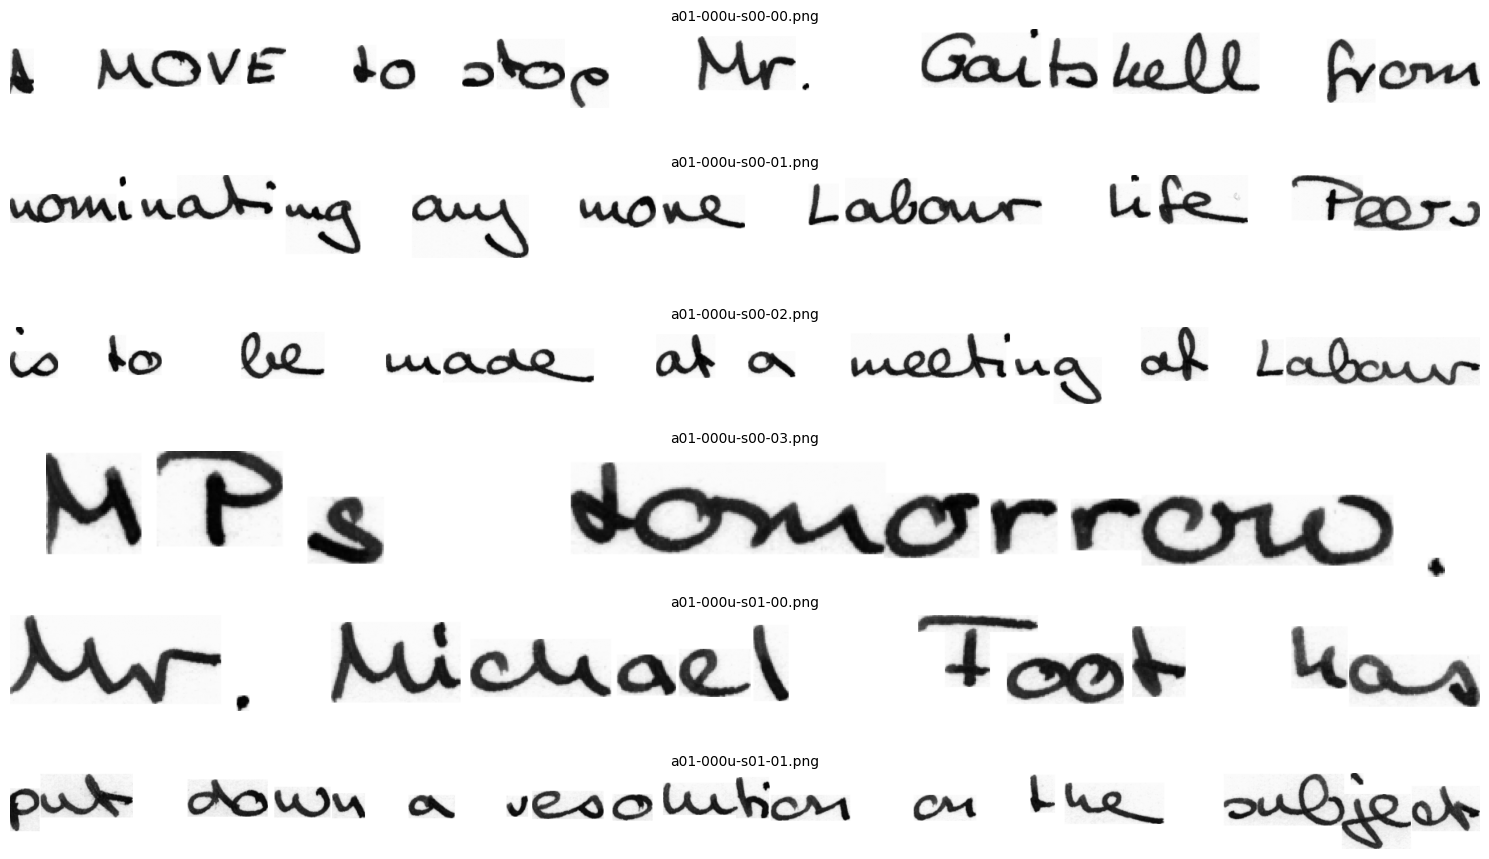

In [18]:
fig, axes = plt.subplots(6, 1, figsize=(15, 9))

for i in range(6):

    dosya_adi = df.iloc[i]["dosya"]
    resim_yolu = os.path.join(goruntu_yolu, dosya_adi)

    resim = Image.open(resim_yolu).convert("L")

    axes[i].imshow(resim, cmap="gray")
    axes[i].set_title(dosya_adi, fontsize=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## ✏️ 3. Veri İşleme ve Hazırlık (Data Processing & Preparation)

Bu aşamada IAM Handwriting Database veri setindeki el yazısı görüntüleri, CNN modelinin eğitiminde kullanılabilecek şekilde hazırlanacaktır.

**Yapılacak İşlemler:**

- **Yazar Seçimi (Writer Selection):**
  Veri setindeki 50 yazar incelenerek yeterli görüntüye ve farklı belgelere sahip 10 yazarın seçilmesi.

- **Yeniden Boyutlandırma (Image Resizing):**
  El yazısı görüntülerinin en-boy oranı korunarak CNN modeline uygun boyutlara getirilmesi.

- **Normalizasyon (Normalization):**
  Görüntülerin gri tonlamaya dönüştürülmesi ve piksel değerlerinin `[0, 255]` aralığından `[0, 1]` aralığına çekilmesi.

- **Etiketleme (Label Encoding):**
  Görüntülerin yazar kimlikleriyle eşleştirilmesi ve seçilen 10 yazarın `0–9` arasında sınıf etiketlerine dönüştürülmesi.

- **Eğitim / Doğrulama / Test Ayrımı (Train–Validation–Test Split):**
  Görüntülerin eğitim, doğrulama ve test kümelerine ayrılması. Aynı belgeye ait görüntülerin farklı kümelere karışmasının önlenmesi.

- **Veri Kontrolü ve Görselleştirme (Data Visualization):**
  Veri kümelerindeki görüntü ve yazar dağılımlarının incelenmesi, ön işleme uygulanmış örneklerin görselleştirilmesi.

In [19]:
with open(form_dosyasi, "r", encoding="utf-8") as f:
    for i in range(25):
        satir = f.readline()
        if not satir:
            break
        print(satir.rstrip())

a01-000u 000 2 prt 7 5 52 36
a01-000x 001 2 all 6 6 52 52
a01-003 002 3 prt 11 10 81 71
a01-003u 000 3 prt 11 10 80 73
a01-003x 003 3 prt 9 6 82 56
a01-007 004 3 all 9 9 69 69
a01-007u 000 3 all 10 10 68 68
a01-007x 003 3 all 8 8 69 69
a01-011 005 2 prt 7 6 68 58
a01-011u 000 2 all 10 10 68 68
a01-011x 006 2 prt 9 1 68 10
a01-014 007 5 prt 10 9 76 68
a01-014u 000 5 prt 9 8 59 53
a01-014x 008 5 all 10 10 76 76
a01-020 009 5 all 9 9 68 68
a01-020u 000 5 all 10 10 68 68
a01-020x 010 5 all 9 9 69 69
a01-026 009 3 prt 10 8 77 62
a01-026u 000 3 all 11 11 77 77
a01-026x 008 3 prt 10 8 78 63
a01-030 005 7 prt 8 6 85 63
a01-030u 000 7 prt 11 10 85 75
a01-030x 010 6 prt 9 8 76 68
a01-038 007 4 prt 13 12 86 77
a01-038x 011 4 prt 9 5 82 43


In [20]:
df_aday = df[
    (df["writer_id"] != 0) &
    (df["writer_id"].notna())].copy()

yazar_istatistikleri = (
    df_aday.groupby("writer_id").agg(
        goruntu_sayisi=("dosya", "count"),
        form_sayisi=("form_id", "nunique")))

uygun_yazarlar = yazar_istatistikleri[
    yazar_istatistikleri["form_sayisi"] >= 3]

secili_yazarlar = (
    uygun_yazarlar
    .sort_values("goruntu_sayisi", ascending=False)
    .head(10)
    .index)

df_secili = df_aday[
    df_aday["writer_id"].isin(secili_yazarlar)].copy()

print("Seçilen yazar sayısı:", df_secili["writer_id"].nunique())
print("Toplam görüntü:", len(df_secili))

display(uygun_yazarlar.loc[secili_yazarlar])

Seçilen yazar sayısı: 10
Toplam görüntü: 1208


,goruntu_sayisi,form_sayisi
writer_id,,
588,133,10
634,133,9
671,129,10
551,129,10
552,125,10
384,117,10
670,116,10
153,111,10
154,108,10


In [21]:
display(df_secili.head())

,dosya,form_id,writer_id
1127,c03-000d-s00-00.png,c03-000d,153
1128,c03-000d-s00-01.png,c03-000d,153
1129,c03-000d-s00-02.png,c03-000d,153
1130,c03-000d-s01-00.png,c03-000d,153
1131,c03-000d-s01-01.png,c03-000d,153


In [22]:
boyutlar = []

for dosya in df["dosya"]:
    resim_yolu = os.path.join(
        goruntu_yolu,
        dosya)
    with Image.open(resim_yolu) as resim:
        genislik, yukseklik = resim.size
    boyutlar.append({
        "dosya": dosya,
        "genislik": genislik,
        "yukseklik": yukseklik})

In [23]:
boyut_df = pd.DataFrame(boyutlar)

In [24]:
boyut_df.head(10)

,dosya,genislik,yukseklik
0,a01-000u-s00-00.png,1661,89
1,a01-000u-s00-01.png,1850,105
2,a01-000u-s00-02.png,1986,105
3,a01-000u-s00-03.png,733,66
4,a01-000u-s01-00.png,1044,68
5,a01-000u-s01-01.png,1830,94
6,a01-000u-s01-02.png,1854,88
7,a01-000u-s01-03.png,2051,87
8,a01-003u-s00-00.png,1938,106
9,a01-003u-s00-01.png,1837,103


In [25]:
boyut_df[["genislik", "yukseklik"]].describe()

,genislik,yukseklik
count,4899.000000,4899.000000
mean,1353.595836,110.632374
std,554.429175,33.991078
min,9.000000,8.000000
25%,905.500000,85.000000
50%,1633.000000,108.000000
75%,1782.000000,131.000000
max,2260.000000,337.000000


In [26]:
hedef_genislik = 256
hedef_yukseklik = 64

def goruntu_hazirla(dosya_yolu):

    resim = Image.open(dosya_yolu).convert("L")
    resim.thumbnail(
        (hedef_genislik, hedef_yukseklik),
        Image.Resampling.LANCZOS)
    arka_plan = Image.new(
        "L",
        (hedef_genislik, hedef_yukseklik),
        255)

    x = (hedef_genislik - resim.width) // 2
    y = (hedef_yukseklik - resim.height) // 2
    arka_plan.paste(resim, (x, y))
    return np.array(arka_plan)

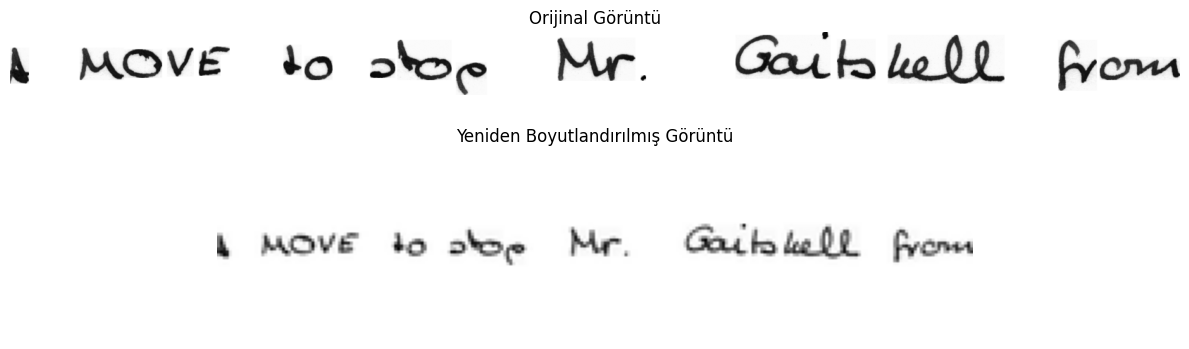

In [27]:
ornek_dosya = df.iloc[0]["dosya"]
ornek_yol = os.path.join(
    goruntu_yolu,
    ornek_dosya)
orijinal = Image.open(ornek_yol).convert("L")
islenmis = goruntu_hazirla(ornek_yol)

fig, axes = plt.subplots(2, 1, figsize=(12, 4))

axes[0].imshow(orijinal, cmap="gray")
axes[0].set_title("Orijinal Görüntü")
axes[0].axis("off")

axes[1].imshow(islenmis, cmap="gray")
axes[1].set_title("Yeniden Boyutlandırılmış Görüntü")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [28]:
ornek_goruntu = goruntu_hazirla(ornek_yol)
ornek_normalize = (ornek_goruntu.astype("float32") / 255.0)

In [29]:
label_encoder = LabelEncoder()

df_secili["label"] = label_encoder.fit_transform(df_secili["writer_id"])

In [30]:
display(df_secili[["dosya", "writer_id", "label"]].head(10))

,dosya,writer_id,label
1127,c03-000d-s00-00.png,153,0
1128,c03-000d-s00-01.png,153,0
1129,c03-000d-s00-02.png,153,0
1130,c03-000d-s01-00.png,153,0
1131,c03-000d-s01-01.png,153,0
1132,c03-000d-s01-02.png,153,0
1133,c03-000d-s01-03.png,153,0
1134,c03-000d-s01-04.png,153,0
1135,c03-000d-s01-05.png,153,0
1136,c03-000e-s00-00.png,154,1


In [31]:
train_parcalar = []
val_parcalar = []
test_parcalar = []

In [32]:
for yazar in df_secili["writer_id"].unique():

    yazar_df = df_secili[df_secili["writer_id"] == yazar]
    yazar_formlari = yazar_df["form_id"].unique()
    rng = np.random.default_rng(42)
    yazar_formlari = rng.permutation(yazar_formlari)

    n = len(yazar_formlari)

    if n < 3:
        raise ValueError(
            f"Yazar {yazar} için yeterli form bulunamadı.")

    n_val = max(1, round(n * 0.10))
    n_test = max(1, round(n * 0.10))

    train_formlari = yazar_formlari[:n - n_val - n_test]
    val_formlari = yazar_formlari[n - n_val - n_test:n - n_test]
    test_formlari = yazar_formlari[n - n_test:]

    train_parcalar.append(
        yazar_df[yazar_df["form_id"].isin(train_formlari)])

    val_parcalar.append(
        yazar_df[yazar_df["form_id"].isin(val_formlari)])

    test_parcalar.append(
        yazar_df[yazar_df["form_id"].isin(test_formlari)])

In [33]:
train_df = pd.concat(train_parcalar).reset_index(drop=True)
val_df = pd.concat(val_parcalar).reset_index(drop=True)
test_df = pd.concat(test_parcalar).reset_index(drop=True)

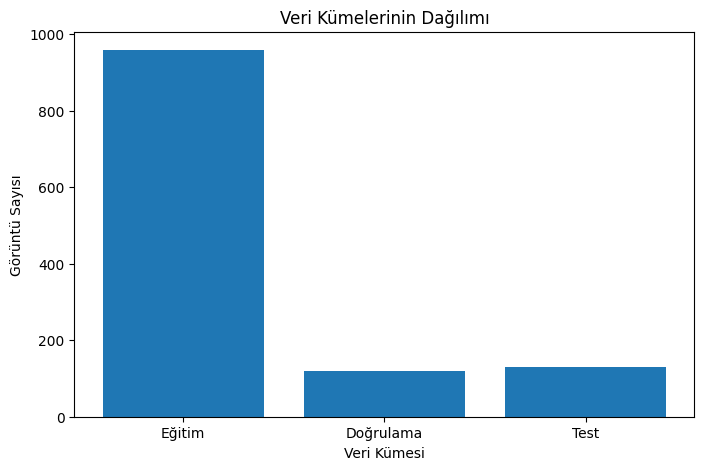

In [34]:
kume_isimleri = ["Eğitim", "Doğrulama", "Test"]

goruntu_sayilari = [
    len(train_df),
    len(val_df),
    len(test_df)]

plt.figure(figsize=(8, 5))

plt.bar(kume_isimleri, goruntu_sayilari)

plt.title("Veri Kümelerinin Dağılımı")
plt.xlabel("Veri Kümesi")
plt.ylabel("Görüntü Sayısı")

plt.show()

In [35]:
def veri_hazirla(tablo):

    x = []
    y = []

    for _, satir in tablo.iterrows():

        dosya_yolu = os.path.join(
            goruntu_yolu,
            satir["dosya"])

        goruntu = goruntu_hazirla(dosya_yolu)

        goruntu = goruntu.astype("float32") / 255.0

        goruntu = np.expand_dims(goruntu, axis=-1)

        x.append(goruntu)
        y.append(satir["label"])

    return np.array(x), np.array(y)

In [36]:
x_train, y_train = veri_hazirla(train_df)

In [37]:
x_val, y_val = veri_hazirla(val_df)

In [38]:
x_test, y_test = veri_hazirla(test_df)

In [39]:
print(df_secili["writer_id"].value_counts().sort_index())

writer_id
153    111
154    108
345    107
384    117
551    129
552    125
588    133
634    133
670    116
671    129
Name: count, dtype: int64


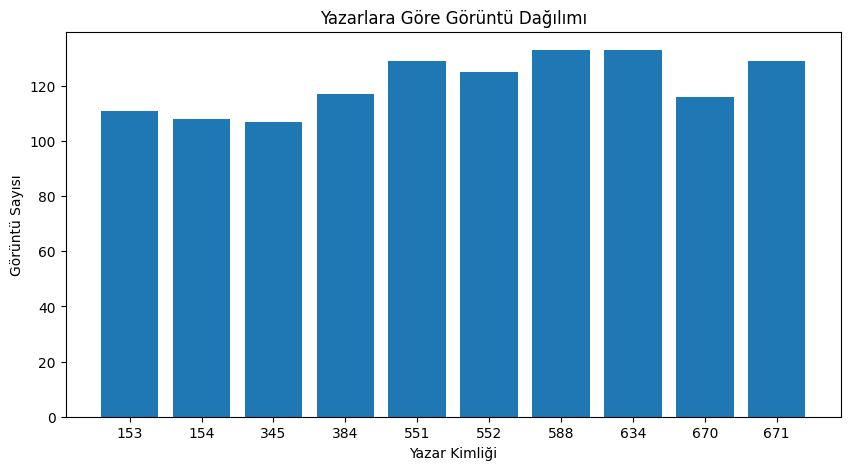

In [40]:
yazar_sayilari = df_secili["writer_id"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(
    yazar_sayilari.index.astype(str),
    yazar_sayilari.values)

plt.title("Yazarlara Göre Görüntü Dağılımı")
plt.xlabel("Yazar Kimliği")
plt.ylabel("Görüntü Sayısı")

plt.show()

## 🧠 4. Model Mimarisi ve Eğitim (Model Architecture & Training)

Bu aşamada, el yazısı görüntülerinden yazar kimliğini tahmin edebilen CNN tabanlı bir sınıflandırma modeli oluşturulacak ve eğitilecektir.

**Yapılacak İşlemler:**

- **Evrişimsel Katmanlar (Conv2D):**
  El yazısı görüntülerindeki çizgi, eğim, harf şekilleri ve yazım özelliklerinin öğrenilmesi.

- **Aktivasyon Fonksiyonu (ReLU):**
  Modelin doğrusal olmayan özellikleri öğrenmesini sağlamak.

- **Havuzlama Katmanları (MaxPooling2D):**
  Özellik haritalarının boyutlarını küçülterek hesaplama yükünü azaltmak.

- **Seyreltme (Dropout):**
  Modelin eğitim verilerini ezberleme riskini (overfitting) azaltmak.

- **Tam Bağlantılı Katmanlar (Dense):**
  Öğrenilen özelliklerin yazar kimliklerini sınıflandırmak amacıyla kullanılması.

- **Çıkış Katmanı (Softmax):**
  Başlangıçta seçilen 10 yazar için tahmin skorlarının oluşturulması.

- **Modelin Derlenmesi (Model Compilation):**
  Adam optimizasyon algoritması ve Sparse Categorical Crossentropy
  kayıp fonksiyonunun kullanılması.

- **Modelin Eğitilmesi (Model Training):**
  Belirlenen epoch ve batch size değerleriyle modelin eğitilmesi.

- **Eğitim Performansının İncelenmesi:**
  Eğitim ve doğrulama doğruluk (Accuracy) ve kayıp (Loss)
  değerlerinin grafiklerle incelenmesi.

In [48]:
model = Sequential([
    Input(shape=(64, 256, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(10, activation="softmax")])

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 64, 256, 32)         │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 32, 128, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 128, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 16, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 16, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 8, 32, 128)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,474 (431.54 KB)

 Trainable params: 110,474 (431.54 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [52]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=32)

Epoch 1/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 180ms/step - accuracy: 0.1126 - loss: 2.3053 - val_accuracy: 0.1333 - val_loss: 2.2980
Epoch 2/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 165ms/step - accuracy: 0.1335 - loss: 2.2985 - val_accuracy: 0.1667 - val_loss: 2.2966
Epoch 3/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - accuracy: 0.1345 - loss: 2.2888 - val_accuracy: 0.1417 - val_loss: 2.2802
Epoch 4/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 211ms/step - accuracy: 0.1627 - loss: 2.2140 - val_accuracy: 0.1833 - val_loss: 2.1765
Epoch 5/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step - accuracy: 0.2054 - loss: 2.0871 - val_accuracy: 0.1917 - val_loss: 2.0237


In [53]:
history_devam = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=32)

Epoch 1/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step - accuracy: 0.2179 - loss: 2.0102 - val_accuracy: 0.3000 - val_loss: 1.9566
Epoch 2/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step - accuracy: 0.2263 - loss: 1.9667 - val_accuracy: 0.3167 - val_loss: 1.8880
Epoch 3/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 221ms/step - accuracy: 0.2409 - loss: 1.9268 - val_accuracy: 0.2583 - val_loss: 1.8372
Epoch 4/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 222ms/step - accuracy: 0.2649 - loss: 1.9173 - val_accuracy: 0.3000 - val_loss: 1.8973
Epoch 5/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 197ms/step - accuracy: 0.2586 - loss: 1.8876 - val_accuracy: 0.2833 - val_loss: 1.7906


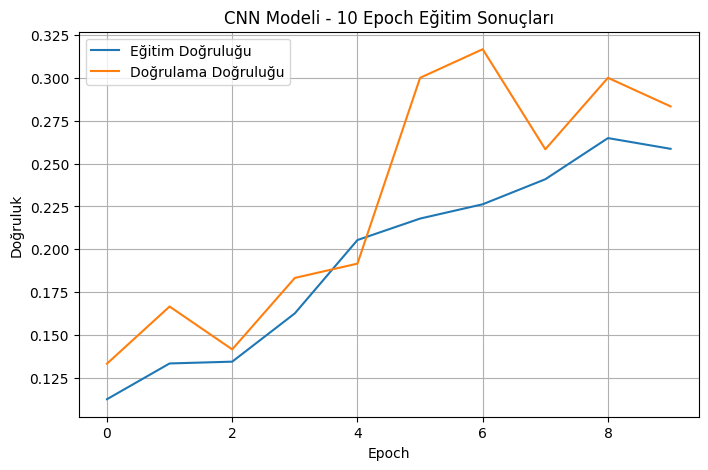

In [54]:
egitim_dogruluk = (
    history.history["accuracy"] +
    history_devam.history["accuracy"])

dogrulama_dogruluk = (
    history.history["val_accuracy"] +
    history_devam.history["val_accuracy"])

plt.figure(figsize=(8, 5))

plt.plot(egitim_dogruluk, label="Eğitim Doğruluğu")
plt.plot(dogrulama_dogruluk, label="Doğrulama Doğruluğu")

plt.xlabel("Epoch")
plt.ylabel("Doğruluk")
plt.title("CNN Modeli - 10 Epoch Eğitim Sonuçları")
plt.legend()
plt.grid(True)

plt.show()